# SECTION 1: INSTALLS & IMPORTS

In [11]:
!pip install groq requests pillow -q

# Standard library
import os
import base64        # encode image so the API can receive it
import json          # parse structured JSON from the model

# Third-party
import requests
from PIL import Image
from io import BytesIO

# Groq SDK
from groq import Groq

# Colab helpers
from google.colab import files
from IPython.display import display, Markdown

# SECTION 2: API KEY SETUP

In [12]:
GROQ_API_KEY = ""    # ← paste your Groq key here

# Create the Groq client — reused in every section
client = Groq(api_key=GROQ_API_KEY)

# Model we'll use for vision (identifying what's in the photo)
# llama-4-scout-17b-16e-instruct supports image input and is free
VISION_MODEL = "meta-llama/llama-4-scout-17b-16e-instruct"

# Model we'll use for text synthesis (generating the final facts)
# llama3-70b is powerful and free on Groq
TEXT_MODEL = "llama-3.3-70b-versatile"

print(" Groq client ready!")
print(f"   Vision model : {VISION_MODEL}")
print(f"   Text model   : {TEXT_MODEL}")

 Groq client ready!
   Vision model : meta-llama/llama-4-scout-17b-16e-instruct
   Text model   : llama-3.3-70b-versatile


# SECTION 3: LOCATION DETECTION

In [13]:
MANUAL_LOCATION = "Nachikatsuura, Higashimuro District, Wakayama"

def detect_location_by_ip():
    try:
        resp = requests.get("http://ip-api.com/json/", timeout=5)
        data = resp.json()
        city = data.get("city", "")
        country = data.get("country", "")
        return f"{city}, {country}" if city else country
    except Exception:
        return None

location_str = MANUAL_LOCATION or detect_location_by_ip()
print("Location:", location_str)

Location: Nachikatsuura, Higashimuro District, Wakayama


# SECTION 3: IMAGE UPLOAD & PREVIEW


Upload your Photo


Saving unnamed.webp to unnamed.webp


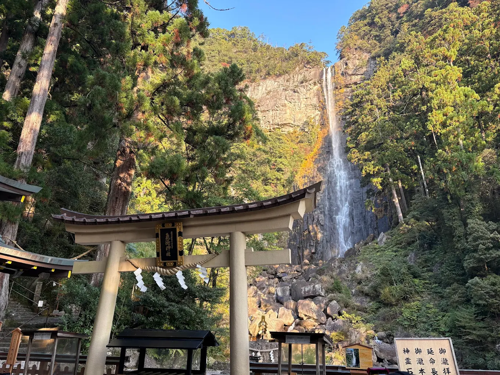


 Uploaded: unnamed.webp
   Size    : 446 KB
   Format  : WEBP

 Image ready to send to AI!


In [3]:
print("Upload your Photo")

# This opens the Colab file upload widget
uploaded = files.upload()

# ── Read the uploaded file ───────────────────────────────────
# files.upload() returns a dict: { filename: bytes }
filename  = list(uploaded.keys())[0]
img_bytes = uploaded[filename]

# ── Preview the image in the notebook ───────────────────────
img = Image.open(BytesIO(img_bytes))
img.thumbnail((500, 500))   # resize just for display, keeps original for API
display(img)
print(f"\n Uploaded: {filename}")
print(f"   Size    : {len(img_bytes) // 1024} KB")
print(f"   Format  : {img.format}")

# ── Encode image to base64 ───────────────────────────────────
# The Groq API cannot receive raw bytes directly.
# Base64 converts the image into a long text string the API understands.
img_b64 = base64.standard_b64encode(img_bytes).decode("utf-8")

# ── Detect the media type from file extension ────────────────
ext = filename.lower().split(".")[-1]
media_type_map = {
    "jpg"  : "image/jpeg",
    "jpeg" : "image/jpeg",
    "png"  : "image/png",
    "webp" : "image/webp",
}
media_type = media_type_map.get(ext, "image/jpeg")

print("\n Image ready to send to AI!")

# SECTION 4: VISION AI — IDENTIFY WHAT'S IN THE PHOTO


In [14]:
import json

vision_response = client.chat.completions.create(
    model=VISION_MODEL,
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:{media_type};base64,{img_b64}"
                    }
                },
                {
                    "type": "text",
                    "text": f"""
You are given an image and a known location.

Known location: {location_str}

Look at the image and identify the main subject.

Return ONLY valid JSON with this exact format:

{{
  "name": "specific name of what you see",
  "category": "landmark / building / nature / food / art / object / animal / street",
  "location_hint": "best guess of location if visible",
  "search_query": "a query to search for historical or interesting facts",
  "description": "one clear sentence describing what this is"
}}

Important:
- Use the known location when forming search_query.
- Even if the location is not visible in the image, still include the known location.
- Do not output anything except JSON.
"""
                }
            ]
        }
    ],
    max_tokens=300,
)

# ── Parse JSON safely ─────────────────────────────
raw = vision_response.choices[0].message.content.strip()

# Remove ```json wrappers if present
if raw.startswith("```"):
    raw = raw.split("```")[1]
    if raw.startswith("json"):
        raw = raw[4:]
    raw = raw.strip().rstrip("```")

subject = json.loads(raw)

# ── Force location into query (hard guarantee) ─────
subject["search_query"] = f"{subject['search_query']} {location_str}"

# ── Print results ─────────────────────────────────
print(f"Identified : {subject['name']}")
print(f"Category   : {subject['category']}")
print(f"Location   : {location_str}")
print(f"Description: {subject['description']}")
print(f"Search term: {subject['search_query']}")

Identified : Nachi Falls
Category   : nature
Location   : Nachikatsuura, Higashimuro District, Wakayama
Description: A large waterfall in a forested area with a Shinto torii gate in the foreground.
Search term: Nachi Falls Nachikatsuura Wakayama Nachikatsuura, Higashimuro District, Wakayama


# SECTION 5: WEB SEARCH — RETRIEVE FACTS

In [15]:
!pip install deep-translator

In [16]:
import requests
from bs4 import BeautifulSoup
from deep_translator import GoogleTranslator

def translate(text, source="auto", target="en"):
    try:
        return GoogleTranslator(source=source, target=target).translate(text)
    except Exception:
        return ""


# ---------- DuckDuckGo Search ----------
def search_local(query, lang="ja"):
    # 1) Translate query to Japanese
    local_query = translate(query, source="en", target=lang)
    if not local_query:
        print("Translation failed, using original query")
        local_query = query

    print("Local query:", local_query)

    url = "https://duckduckgo.com/html/"
    headers = {"User-Agent": "Mozilla/5.0"}
    params = {"q": local_query, "kl": "jp-ja"}

    try:
        r = requests.get(url, params=params, headers=headers, timeout=10)
        soup = BeautifulSoup(r.text, "html.parser")

        snippets = []
        for s in soup.select("a.result__snippet"):
            snippets.append(s.get_text(" ", strip=True))

        if not snippets:
            for s in soup.select("div.result__snippet"):
                snippets.append(s.get_text(" ", strip=True))

        if not snippets:
            for s in soup.select("a.result__a"):
                snippets.append(s.get_text(" ", strip=True))

        combined_jp = "\n".join(snippets[:5])

        # 2) Translate snippets back to English
        combined_en = translate(combined_jp, source="auto", target="en")
        return combined_en

    except Exception as e:
        print("Search error:", e)
        return ""


# ---------- RUN ----------
query = subject.get("search_query", "")
if not query:
    raise ValueError("No search query provided")

print("Searching for:", query)

web_context = search_local(query)

print("Context length:", len(web_context))
print(web_context[:400])

Searching for: Nachi Falls Nachikatsuura Wakayama Nachikatsuura, Higashimuro District, Wakayama
Local query: 那智の滝 和歌山県那智勝浦町 和歌山県東牟婁郡那智勝浦町
Context length: 1948
Nachi Falls is a waterfall spanning the middle reaches of the Nachi River in Nachikatsuura Town, Higashimauro District, Wakayama Prefecture. It falls along an almost vertical cliff made of quartz porphyry, with a width of 13 meters at the entrance and a drop of 133 meters to the basin, which can be seen from the Kumano Sea.[1]
Location: Nachiyama, Nachikatsuura-cho, Higashimauro-gun, Wakayama Pref


# SECTION 7: RAG SYNTHESIS — GENERATE INTERESTING FACTS

In [17]:
print("Synthesizing insights...\n")

# ── Build location context string ───────────────────────────
location_parts = []
if location_str:
    location_parts.append(f"The user is currently in: {location_str}.")
if image_location:
    location_parts.append(f"The photo appears to be from: {image_location}.")
location_context = " ".join(location_parts) or "Location unknown."

# ── Build the RAG prompt ─────────────────────────────────────
# We explicitly tell the model to use the retrieved text,
# not its own training memory. This is the core of RAG.
rag_prompt = f"""You are a knowledgeable and engaging guide who gives fascinating, specific facts about things people photograph.

SUBJECT IDENTIFIED FROM PHOTO:
Name        : {subject['name']}
Category    : {subject['category']}
Description : {subject['description']}

USER LOCATION:
{location_context}

RETRIEVED INFORMATION (use this as your primary source):
{web_context[:3500]}

---

TASK:
Using the retrieved information above as your main source, write exactly 5 interesting facts about "{subject['name']}".

Rules:
- Pull specific numbers, dates, and details from the retrieved text
- Do NOT just repeat generic well-known facts
- If the user's location has any connection to the subject, mention it
- Each fact should have a short bold title
- End with one practical tip: what to look for or do related to this subject

Format your response in clean markdown."""

# ── Call the text model ──────────────────────────────────────
synthesis = client.chat.completions.create(
    model=TEXT_MODEL,
    messages=[
        {
            "role": "system",
            "content": "You are an expert researcher and storyteller. Always base your answers on the provided retrieved text."
        },
        {
            "role": "user",
            "content": rag_prompt
        }
    ],
    max_tokens=1000,
    temperature=0.7,   # slight creativity — 0 = robotic, 1 = very creative
)

result = synthesis.choices[0].message.content

Synthesizing insights...



# SECTION 8: DISPLAY RESULTS

In [18]:
display(Markdown("---"))
display(Markdown(f"# {subject['name']}"))
display(Markdown(f"**Category:** {subject['category']}"))
display(Markdown(f"**{subject['description']}**"))
if location_str:
    display(Markdown(f"*Your location: {location_str}*"))
display(Markdown("---"))
display(Markdown(result))

---

# Nachi Falls

**Category:** nature

**A large waterfall in a forested area with a Shinto torii gate in the foreground.**

*Your location: Nachikatsuura, Higashimuro District, Wakayama*

---

### Introduction to Nachi Falls
Nachi Falls is a remarkable waterfall located in Nachikatsuura Town, Wakayama Prefecture, Japan, which is also where you are currently situated. Here are 5 interesting facts about this natural wonder:

* **Height and Width**: Nachi Falls has a drop of 133 meters and a width of 13 meters at the entrance, making it an impressive sight to behold.
* **Sacred Significance**: This waterfall has been considered sacred since ancient times and is worshiped as a central figure in Kumano religion, with records of its enshrinement dating back to Emperor Jimmu, as mentioned in the Kojiki.
* **Accessibility**: You can reach Nachi Falls by taking a 25-minute bus ride from JR Kii-Katsuura Station, followed by a 1-minute walk from the "Nachi no Taki-mae" bus stop, making it a convenient destination to visit.
* **World Heritage Site**: Nachi Falls is part of the World Heritage Site "Sacred Sites and Pilgrimage Routes in the Kii Mountains", recognizing its cultural and historical significance.
* **Seasonal Landscapes**: The waterfall offers breathtaking views throughout the year, with distinct landscapes during spring, autumn, rainy season, and winter, making it a great spot to visit regardless of the time of year.

As you visit Nachi Falls, be sure to look for the **Shrine Stage** which offers spectacular views of the waterfall, and take a moment to appreciate the negative ions and sacred water that surround this natural wonder.